<a href="https://colab.research.google.com/github/HaiderCaballero/Estadistica1_Tarea_2/blob/main/Tarea_3_Estad%C3%ADstica_Descriptiva_en_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TAREA 3: ESTADÍSTICA DESCRIPTIVA EN PYTHON**

**INTEGRANTES:**

1.   MARIA PAULA ANAYA PARRA - 2251445.
2.   AARON JOEL RUEDA ARIZA - 2250766.
3.   HAIDER DANIEL CABALLERO ROJAS - 2251827.
4.   JOSE BENICIO VIVEROS BELTRAN - 2250783.

**PROFESOR:**
* ANDRES SEBASTIAN RIOS GUTIERREZ.

**Curso:** Estadistica I - **Grupo:** F1.

# **Estadística descriptiva para variables cualitativas**

*  Gráficos para datos univariados cualitativos.
*  Proporciones asociadas a los valores de una variable cualitativa.

**Introducción y Origen de los Datos**

El presente análisis utiliza la base de datos de Estadísticas Vitales (Nacimientos 2024) proveniente del DANE. Estos microdatos se recolectan a partir de los certificados de nacido vivo en Colombia. Nuestro objetivo es analizar el comportamiento univariado y bivariado de las variables T_GES (Tiempo de gestación) y TALLA_NAC (Talla al nacimiento), aplicando estadística descriptiva y contrastes de independencia.

In [ ]:
# Importación de librerías para manipulación y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Configuración de los gráficos (para asegurar buena resolución según la rúbrica)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120

# Código de carga del profesor
from google.colab import files
uploaded = files.upload()

import io
io_csv = io.BytesIO(uploaded['BD-EEVV-Nacimientos-2024.csv'])
tabla = pd.read_csv(io_csv, sep=",", index_col=0, encoding='latin-1')

Saving BD-EEVV-Nacimientos-2024.csv to BD-EEVV-Nacimientos-2024.csv


**Limpieza de Datos**

De acuerdo con los manuales de diccionario de datos del DANE, variables como la talla o el tiempo de gestación pueden contener valores de relleno (como 9, 99 o 999) que representan respuestas en la categoría de "Ignorado" o "Sin información". Para evitar sesgos estadísticos y garantizar que el análisis refleje fenómenos biológicos reales, se procede a filtrar estos valores anómalos antes de realizar los cálculos de proporciones.

In [ ]:
import pandas as pd
import io

io_csv = io.BytesIO(uploaded['BD-EEVV-Nacimientos-2024.csv'])

# Leemos forzosamente con coma y SIN index_col para no desfasar la tabla
tabla = pd.read_csv(io_csv, sep=",", encoding='latin-1')

# Limpiamos posibles espacios fantasma en los nombres
tabla.columns = tabla.columns.str.strip()

print("Muestra de columnas detectadas:")
print(tabla.columns[:15].tolist()) # Solo para verificar que ya se separaron

Muestra de columnas detectadas:
['COD_DPTO', 'COD_MUNIC', 'AREANAC', 'SIT_PARTO', 'OTRO_SIT', 'SEXO', 'PESO_NAC', 'TALLA_NAC', 'ANO', 'MES', 'ATEN_PAR', 'T_GES', 'T_GES_AGRU_CIE', 'NUMCONSUL', 'TIPO_PARTO']


In [ ]:
# Convertimos las columnas a valores numéricos (por si el DANE las subió como texto)
tabla['T_GES'] = pd.to_numeric(tabla['T_GES'], errors='coerce')
tabla['TALLA_NAC'] = pd.to_numeric(tabla['TALLA_NAC'], errors='coerce')

print("Máximo en T_GES original:", tabla['T_GES'].max())
print("Máximo en TALLA_NAC original:", tabla['TALLA_NAC'].max())

# Filtramos valores "Ignorados" del DANE usando el nombre correcto: T_GES
tabla_limpia = tabla[(tabla['T_GES'] != 9) & (tabla['T_GES'] != 99) & (tabla['T_GES'] < 50)]
tabla_limpia = tabla_limpia[(tabla_limpia['TALLA_NAC'] != 9) & (tabla_limpia['TALLA_NAC'] != 99) & (tabla_limpia['TALLA_NAC'] < 70)]

# Eliminamos cualquier dato nulo (NaN) que haya quedado en estas columnas
tabla_limpia = tabla_limpia.dropna(subset=['T_GES', 'TALLA_NAC'])

print(f"Registros originales: {len(tabla)}. Registros tras limpieza: {len(tabla_limpia)}.")

Máximo en T_GES original: 9
Máximo en TALLA_NAC original: 9
Registros originales: 453901. Registros tras limpieza: 443622.


***1. ¿Cómo se comporta la variable tiempo de gestación (TGES)?***

A continuación, extraemos las proporciones y visualizamos la distribución de frecuencias para identificar los valores modales, observando en qué etapa ocurren predominantemente los nacimientos vivos en Colombia.

Proporciones de T_GES (%):
 T_GES
1     0.00
2     0.38
3    27.35
4    72.04
5     0.08
6     0.14
Name: proportion, dtype: float64


/tmp/ipykernel_421/404299376.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=prop_tges.index, y=prop_tges.values, palette='viridis')


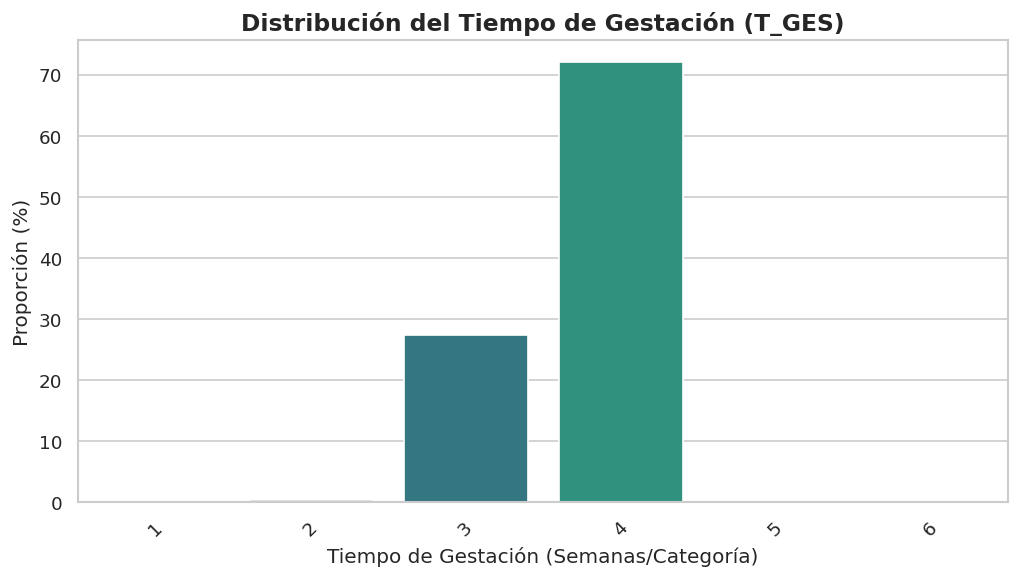

In [ ]:
# 1. Proporciones para cada valor de la variable TGES (en porcentaje)
prop_tges = tabla_limpia['T_GES'].value_counts(normalize=True).sort_index() * 100
print("Proporciones de T_GES (%):\n", round(prop_tges, 2))

# 2. Gráfico estadístico de TGES
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=prop_tges.index, y=prop_tges.values, palette='viridis')
plt.title('Distribución del Tiempo de Gestación (T_GES)', fontsize=14, fontweight='bold')
plt.xlabel('Tiempo de Gestación (Semanas/Categoría)', fontsize=12)
plt.ylabel('Proporción (%)', fontsize=12)
plt.xticks(rotation=45)
plt.show()

**Análisis de Resultados (TGES)**

Al analizar la distribución del tiempo de gestación, se observa que la inmensa mayoría de los nacimientos en Colombia llegan a término. El 72.04% de los nacimientos ocurren en la categoría 4, seguida por un 27.35% en la categoría 3. Los nacimientos prematuros extremos o postérmino (categorías 1, 2, 5 y 6) representan proporciones ínfimas, sumando en conjunto menos del 0.6% de los casos.

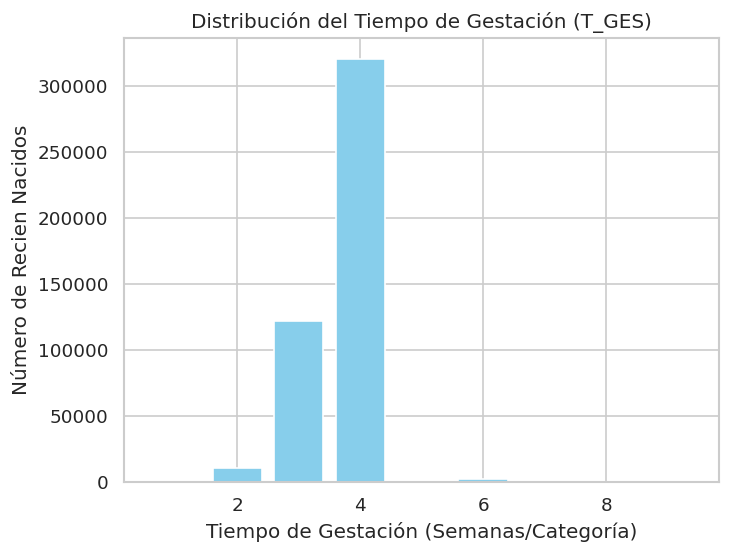

In [ ]:
# Diagrama de barras para la variable TGES
x_values = tabla['T_GES'].unique()
y_values = tabla['T_GES'].value_counts().tolist()
plt.bar(x_values, y_values, color = "skyblue")
plt.title('Distribución del Tiempo de Gestación (T_GES)')
ax = plt.subplot()  # Axis
ax.set_xlabel('Tiempo de Gestación (Semanas/Categoría)')
ax.set_ylabel('Número de Recien Nacidos')
plt.show()

El valor de 38 a 41 semanas es el rango de tiempo donde se tienen alrededor de mas de 300.000 niños recién nacidos. Seguido del rango de tiempo de 28 a 37 semanas se tienen aproximadamente 100.000 niños de recién nacidos.

***2. ¿Cómo se comporta la variable talla de nacimiento (TALLA_NAC)?***

Realizamos el mismo procedimiento para la talla del recién nacido. Al ser una variable con mayor dispersión (más valores discretos posibles), utilizamos un histograma con estimación de densidad y proporciones.

Proporciones de TALLA_NAC (%):
 TALLA_NAC
1     0.00
2     0.05
3     1.02
4    47.94
5    50.99
6     0.00
Name: proportion, dtype: float64


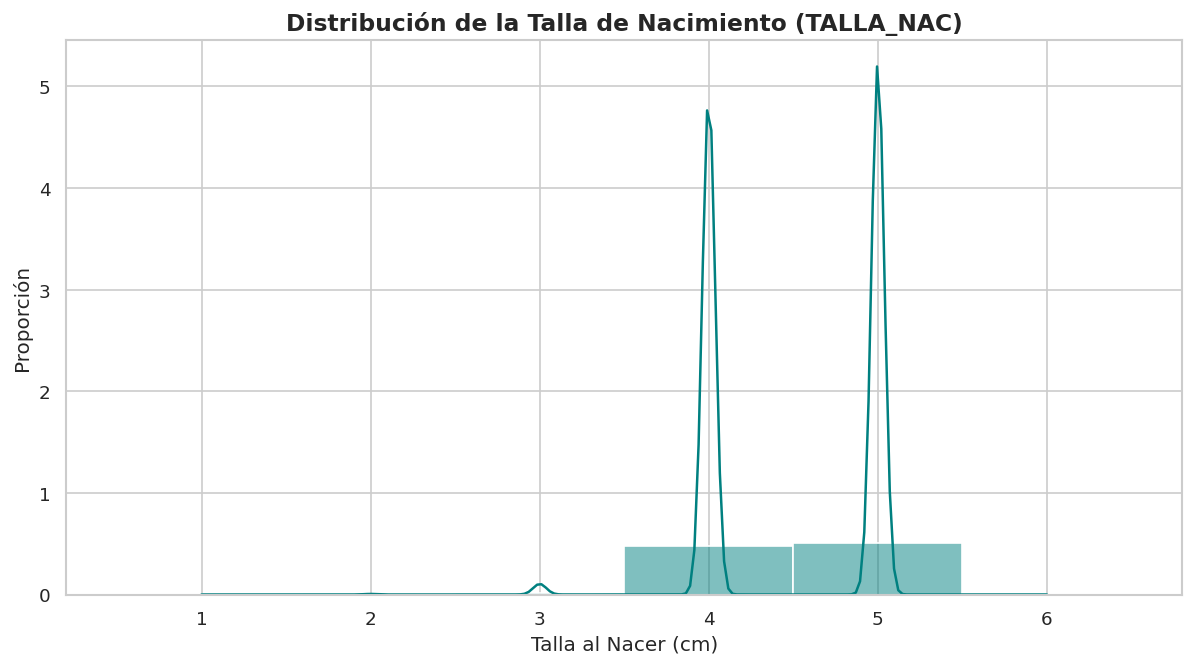

In [ ]:
# 1. Proporciones para cada valor de TALLA_NAC
prop_talla = tabla_limpia['TALLA_NAC'].value_counts(normalize=True).sort_index() * 100
print("Proporciones de TALLA_NAC (%):\n", round(prop_talla, 2))

# 2. Gráfico estadístico
plt.figure(figsize=(12, 6))
sns.histplot(data=tabla_limpia, x='TALLA_NAC', stat='proportion', discrete=True, color='teal', kde=True)
plt.title('Distribución de la Talla de Nacimiento (TALLA_NAC)', fontsize=14, fontweight='bold')
plt.xlabel('Talla al Nacer (cm)', fontsize=12)
plt.ylabel('Proporción', fontsize=12)
plt.show()

**Análisis de Resultados (TALLA_NAC)**

La distribución de la talla al nacer presenta un comportamiento bimodal fuertemente concentrado. Las tallas se agrupan casi exclusivamente en dos categorías: la categoría 4 (que concentra el 47.94% de los casos) y la categoría 5 (con el 50.99%). Las demás categorías de talla son estadísticamente marginales (1.07% en conjunto), lo que indica una alta estandarización biológica en la longitud de los neonatos a nivel nacional.

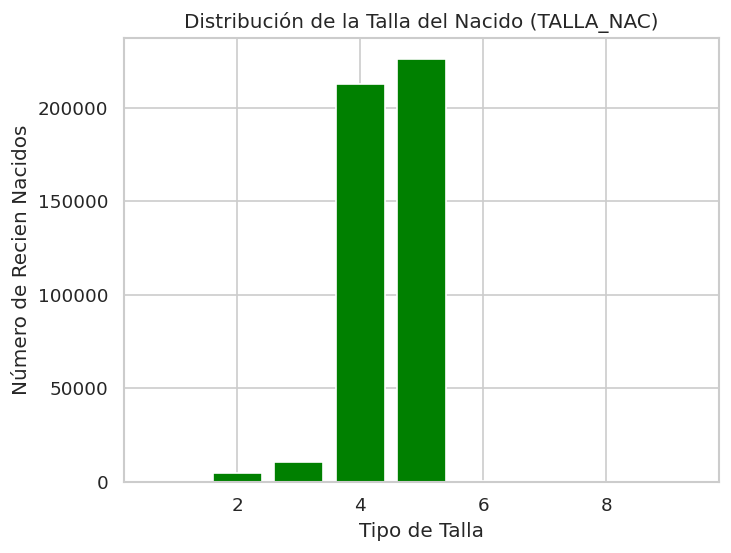

In [ ]:
# Diagrama de barras para la variable TALLA_NAC
x_values = tabla['TALLA_NAC'].unique()
y_values = tabla['TALLA_NAC'].value_counts().tolist()
plt.bar(x_values, y_values, color = "green")
plt.title('Distribución de la Talla del Nacido (TALLA_NAC)')
ax = plt.subplot()  # Axis
ax.set_xlabel('Tipo de Talla')
ax.set_ylabel('Número de Recien Nacidos')
plt.show()

El valor de 50 a 59 semanas es el rango de talla donde se tienen alrededor de mas de 220.000 niños recién nacidos. Seguido del rango de talla de 40 a 49 semanas se tienen aproximadamente 210.000 niños de recién nacidos.

***3. ¿Alguna variable depende de la otra? ¿Están asociadas?***

Desde el contexto biológico, es natural hipotetizar que a mayor tiempo de gestación, el feto tiene más tiempo para desarrollarse y, por ende, nace con mayor talla. Para comprobar estadísticamente esta asociación, procedemos a:
1. Crear una tabla de contingencia (frecuencias conjuntas cruzadas).
2. Visualizar mediante un Mapa de Calor.
3. Calcular las probabilidades condicionales $P(\text{Talla} \mid \text{Tiempo de Gestación})$.

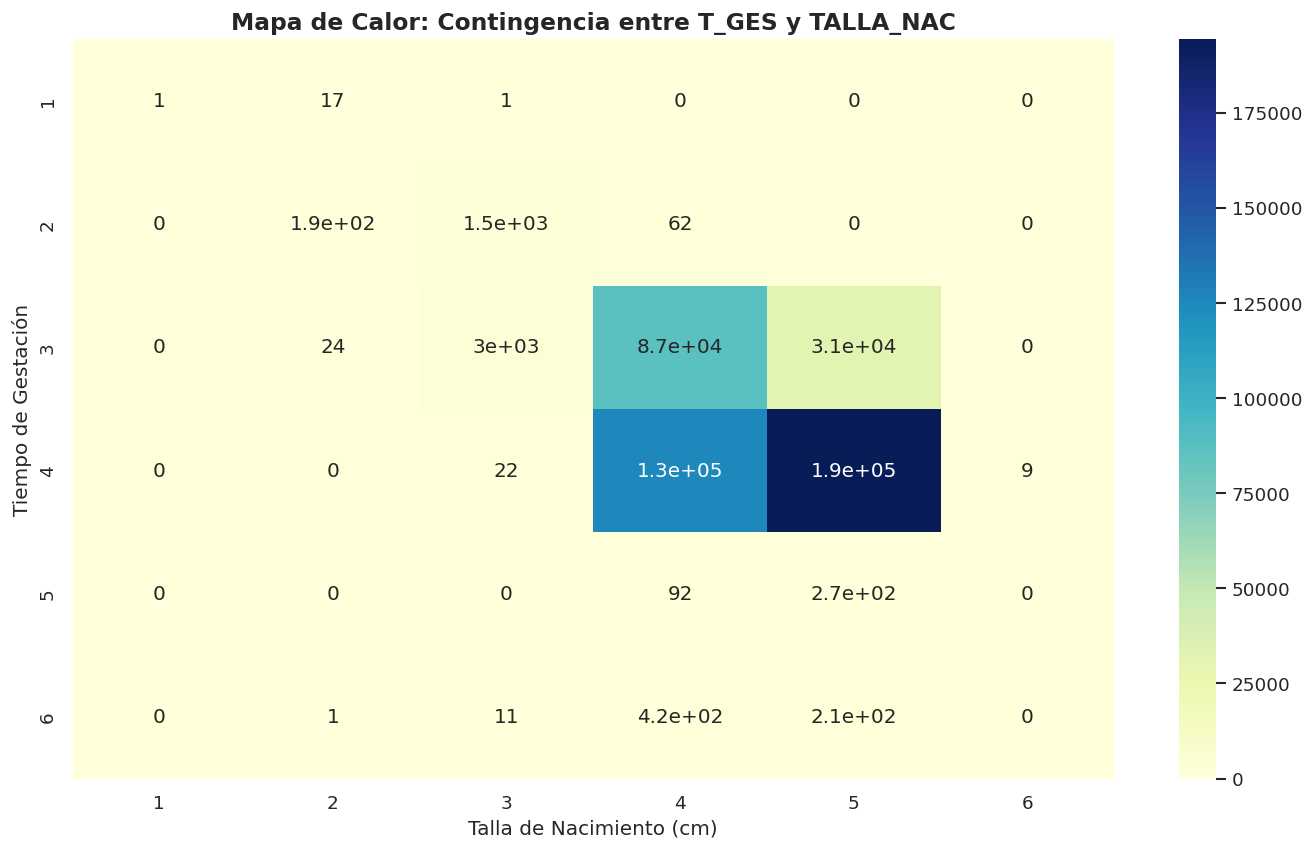

Probabilidades Condicionales P(TALLA_NAC | T_GES) en %:


TALLA_NAC,1,2,3,4,5,6
T_GES,,,,,,
1,5.26,89.47,5.26,0.00,0.00,0.0
2,0.00,10.91,85.45,3.64,0.00,0.0
3,0.00,0.02,2.49,71.56,25.94,0.0
4,0.00,0.00,0.01,39.20,60.79,0.0
5,0.00,0.00,0.00,25.27,74.73,0.0
6,0.00,0.16,1.72,65.37,32.76,0.0


In [ ]:
# 1. Tabla de contingencia (Frecuencias absolutas conjuntas)
contingencia = pd.crosstab(tabla_limpia['T_GES'], tabla_limpia['TALLA_NAC'])

# 2. Gráfico de la tabla de contingencia (Mapa de calor)
plt.figure(figsize=(14, 8))
sns.heatmap(contingencia, cmap='YlGnBu', annot=True)
plt.title('Mapa de Calor: Contingencia entre T_GES y TALLA_NAC', fontsize=14, fontweight='bold')
plt.xlabel('Talla de Nacimiento (cm)', fontsize=12)
plt.ylabel('Tiempo de Gestación', fontsize=12)
plt.show()

# 3. Probabilidades condicionales: Proporciones condicionadas a la fila (TGES)
# Representa P(TALLA_NAC = y | TGES = x)
prob_cond = pd.crosstab(tabla_limpia['T_GES'], tabla_limpia['TALLA_NAC'], normalize='index') * 100
print("Probabilidades Condicionales P(TALLA_NAC | T_GES) en %:")
display(round(prob_cond, 2)) # Usa display en colab para renderizar la tabla limpia

**Prueba de Hipótesis Chi-Cuadrado ($\chi^2$)**

Para verificar si existe dependencia estadística significativa, planteamos:
1. $H_0$: TGES y TALLA_NAC son independientes.
2. $H_1$: Existe dependencia (asociación) entre TGES y TALLA_NAC.
3. Además, usaremos la medida de fuerza de asociación basada en el estadístico $\chi^2$, conocida como el Coeficiente V de Cramer, el cual varía entre 0 (independencia total) y 1 (dependencia perfecta).

In [ ]:
import math
# Prueba Chi Cuadrado
chi2, p_valor, grados_libertad, esperados = stats.chi2_contingency(contingencia)

print("--- RESULTADOS PRUEBA CHI-CUADRADO ---")
print(f"Estadístico Chi-Cuadrado: {chi2:.2f}")
print(f"Valor p (p-value): {p_valor:.4e}")
print(f"Grados de libertad: {grados_libertad}\n")

# Medida de asociación basada en Chi-Cuadrado: V de Cramer
n = contingencia.sum().sum()
min_dim = min(contingencia.shape) - 1
v_cramer = np.sqrt(chi2 / (n * min_dim))

print("--- MEDIDA DE ASOCIACIÓN ---")
print(f"Coeficiente V de Cramer: {v_cramer:.4f}")

--- RESULTADOS PRUEBA CHI-CUADRADO ---
Estadístico Chi-Cuadrado: 259590.43
Valor p (p-value): 0.0000e+00
Grados de libertad: 25

--- MEDIDA DE ASOCIACIÓN ---
Coeficiente V de Cramer: 0.3421


In [ ]:
# Medida de asociación basada en Chi-Cuadrado: Phi
coeficiente_phi = math.sqrt(chi2/ n)
coeficiente_phi

0.7649583659018521

In [ ]:
# Medida de asociación basada en Chi-Cuadrado: Contingencia
coeficiente_contingencia = math.sqrt(chi2/(chi2 + n))
coeficiente_contingencia

0.6075766401227416

**Conclusiones**

1. **Interpretación estadística:** El p-valor arrojado por la prueba Chi-Cuadrado es de 0.00 (menor al nivel de significancia $\alpha = 0.05$). Por lo tanto, se rechaza la hipótesis nula de independencia con una confianza del 95%; existe evidencia estadística sumamente fuerte para afirmar que el tiempo de gestación (T_GES) y la talla al nacer (TALLA_NAC) están asociadas en la población colombiana.

2. **Fuerza de la asociación:** Aunque la asociación es estadísticamente significativa (debido al inmenso tamaño de la muestra de más de 440,000 registros). Se concluye que existe dependencia estadísticamente significativa entre el tiempo de gestación (T_GES) y la talla de nacimiento (TALLA_NAC), cuya fuerza de asociación es discreta (V de Cramer = 0.3421) y moderada (coeficiente_contingencia = 0.6075).

3. **Análisis de probabilidades condicionales y mapa de calor:** La matriz de probabilidades condicionales revela por qué la asociación es moderada. Independientemente de si el bebé nace en la categoría de gestación 3, 4, 5 o 6, su talla casi siempre caerá en las categorías 4 o 5 (concentrando más del 97% de las probabilidades en esos cruces). La dependencia es visible en los casos extremadamente prematuros (categorías de gestación 1 y 2), donde la probabilidad se desplaza hacia tallas muy pequeñas (categoría 2 y 3).

4. **Contexto de los datos:** Estos resultados evidencian que, si bien el tiempo de gestación es un factor asociado al desarrollo físico (longitud) del neonato, en la inmensa mayoría de los embarazos viables en Colombia (categorías 3 a 6), la talla al nacer tiende a estabilizarse en un rango estándar biológico, haciendo que la variabilidad dependa más de otros factores genéticos o nutricionales que no están capturados en este cruce bivariado.